### Segment-Wise ISC Analysis

In [1]:
import numpy as np
import pandas as pd
import os, sys, re
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from pathlib import Path
import glob

try:
    import utils.segment_isc_utils
except ImportError as e:
    print(f"\nSTILL FAILING: {e}")

### Set up Segments and Data

In [7]:
# --- CONFIGURATION ---
SEGMENTS = {
    'PC': {
        1: (9, 54),    # Premise
        2: (55, 205),  # Rising Action
        3: (205, 243), # Climax (38s)
        4: (243, 278), # Resolution (35s)
        5: (279, 319)  # Ending
    },
    'PCM': {
        1: (9, 54),
        2: (55, 205),
        3: (205, 240), # Resolution (35s) - Swapped
        4: (240, 278), # Climax (38s)     - Swapped
        5: (279, 319)
    }
}


current_dir = os.getcwd()
DATA_DIR        = os.path.abspath(os.path.join(current_dir, "../data/02_processed_combined_data"))
CONDITIONS_FILE = os.path.abspath(os.path.join(current_dir, "../data/sub_conditions.csv"))
OUTPUT_DIR      = os.path.abspath(os.path.join(current_dir, "../data/04_analysis/segmented"))

### Run Segment ISC over PC and PCM data

[PC] Found 99 subjects in condition file.
[PCM] Found 99 subjects in condition file.

Analyzing Signal: GSR

Data Length Distribution for GSR:
6381    97
Name: count, dtype: int64
Trimming data to common length: 6381 samples.
Successfully loaded 97 subjects for GSR.


Data Length Distribution for GSR:
6381    98
Name: count, dtype: int64
Trimming data to common length: 6381 samples.
Successfully loaded 98 subjects for GSR.



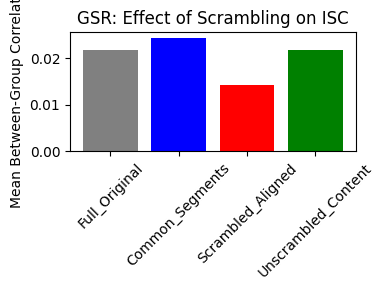

  Finished GSR


In [8]:
signals = ['GSR']#, 'Heart_Rate', 'Gaze_X', 'Gaze_Y', 'Pupil_Mean']
if not os.path.exists(OUTPUT_DIR):
        os.makedirs(OUTPUT_DIR)
        
summary_report = ["# Segmented ISC Analysis Report\n"]
    
# 1. Load All Subjects
pc_subs  = utils.segment_isc_utils.get_subjects_by_condition(CONDITIONS_FILE, 'PC')
pcm_subs = utils.segment_isc_utils.get_subjects_by_condition(CONDITIONS_FILE, 'PCM')
    

for signal in signals:
        print(f"\nAnalyzing Signal: {signal}")
        summary_report.append(f"\n## Signal: {signal}")
        
        signal_out_dir = os.path.join(OUTPUT_DIR, signal)
        if not os.path.exists(signal_out_dir): os.makedirs(signal_out_dir)
        
        try:
            df_pc  = utils.segment_isc_utils.load_physio_data(DATA_DIR, pc_subs, signal_type=signal)
            df_pcm = utils.segment_isc_utils.load_physio_data(DATA_DIR, pcm_subs, signal_type=signal)
        except Exception as e:
            print(f"Error loading data for {signal}: {e}")
            continue
            
        # Ensure same length (trim to min)
        l_pc = df_pc.shape[0]
        l_pcm = df_pcm.shape[0]
        common_len = min(l_pc, l_pcm)
        
        df_pc = df_pc.iloc[:common_len]
        df_pcm = df_pcm.iloc[:common_len]
        
        # --- PREPARE DATASETS ---
        
        # A. Full Concatenated (Condition Blocks)
        # Combine [PC_subs, PCM_subs]
        df_full = pd.concat([df_pc, df_pcm], axis=1)
        
        # B. Segmented Chunks
        segs_pc  = utils.segment_isc_utils.extract_segments(df_pc, SEGMENTS['PC'], common_len)
        segs_pcm = utils.segment_isc_utils.extract_segments(df_pcm, SEGMENTS['PCM'], common_len)
        
        # C. Construct "Common" Data (1,2,5)
        # Concatenate time series of these segments
        common_pc  = pd.concat([segs_pc[1], segs_pc[2], segs_pc[5]], axis=0)
        common_pcm = pd.concat([segs_pcm[1], segs_pcm[2], segs_pcm[5]], axis=0)
        df_common  = pd.concat([common_pc, common_pcm], axis=1)
        
        # D. Construct "Scrambled (Aligned)" Data 
        # PC: 3+4 (Climax then Resolution)
        # PCM: 3+4 (Resolution then Climax) -> But compared by time idx
        scrambled_pc  = pd.concat([segs_pc[3], segs_pc[4]], axis=0)
        scrambled_pcm = pd.concat([segs_pcm[3], segs_pcm[4]], axis=0)
        # Note: They have slightly different lengths in time defs maybe? 
        # PC 3+4 = (38+35)=73s. PCM 3+4 = (35+38)=73s. Total len matches.
        # But boundaries might be slightly off in indices due to rounding.
        # We trim to min length to concatenate safely.
        min_len_sc    = min(scrambled_pc.shape[0], scrambled_pcm.shape[0])
        scrambled_pc  = scrambled_pc.iloc[:min_len_sc]
        scrambled_pcm = scrambled_pcm.iloc[:min_len_sc]
        
        df_scrambled  = pd.concat([scrambled_pc, scrambled_pcm], axis=1)

        # E. Construct "Unscrambled (Content)" Data
        # We want to match PC's sequence (1-2-3-4-5) with PCM's reordered sequence (1-2-[4]-[3]-5)
        # PC 3 (Climax) matches PCM 4 (Climax).
        # PC 4 (Resolution) matches PCM 3 (Resolution).
        
        # Reconstruct PCM as 1-2-4-3-5
        # Careful: PCM seg 4 is Climax. PCM seg 3 is Resolution.
        # PC seg 3 is Climax. PC seg 4 is Resolution.
        # So we want [PCM_1, PCM_2, PCM_4, PCM_3, PCM_5]
        
        unscrambled_pcm_parts = [segs_pcm[1], segs_pcm[2], segs_pcm[4], segs_pcm[3], segs_pcm[5]]
        unscrambled_pcm_ts    = pd.concat(unscrambled_pcm_parts, axis=0)
        
        # PC is just normal 1-2-3-4-5
        unscrambled_pc_ts = pd.concat([segs_pc[1], segs_pc[2], segs_pc[3], segs_pc[4], segs_pc[5]], axis=0)
        
        # Trim to match
        min_len_un         = min(unscrambled_pc_ts.shape[0], unscrambled_pcm_ts.shape[0])
        unscrambled_pc_ts  = unscrambled_pc_ts.iloc[:min_len_un]
        unscrambled_pcm_ts = unscrambled_pcm_ts.iloc[:min_len_un]
        
        df_unscrambled     = pd.concat([unscrambled_pc_ts, unscrambled_pcm_ts], axis=1)

        
        # --- ANALYSIS & PLOTTING ---
        
        datasets = {
            "Full_Original": df_full,
            "Common_Segments": df_common,
            "Scrambled_Aligned": df_scrambled,
            "Unscrambled_Content": df_unscrambled
        }
        
        isc_results = {}
        
        # 1. Block Matrices and Mean ISC
        for name, data in datasets.items():
            # Correlation Matrix
            corr = data.corr().values
            
            # Save Matrix Plot
            plt.figure(figsize=(5, 4))
            # Create labels: PC first then PCM
            # data columns are PC subs then PCM subs
            n_pc = df_pc.shape[1]
            n_pcm = df_pcm.shape[1]
            
            # Heatmap
            sns.heatmap(corr, center=0, cmap='RdBu_r', vmin=-0.5, vmax=0.5) # Capped for visibility
            
            # Draw lines separating conditions
            plt.axvline(n_pc, color='black', linewidth=1)
            plt.axhline(n_pc, color='black', linewidth=1)
            
            plt.title(f"{signal} - {name}")
            plt.tight_layout()
            #plt.show()
            plt.savefig(os.path.join(signal_out_dir, f"matrix_{name}.png"), dpi=300)
            plt.close()
            
            # Calculate Mean ISCs
            # 1. Within PC (Upper Tri)
            pc_block  = corr[:n_pc, :n_pc]
            within_pc = pc_block[np.triu_indices(n_pc, k=1)].mean()
            
            # 2. Within PCM
            pcm_block = corr[n_pc:, n_pc:]
            within_pcm = pcm_block[np.triu_indices(n_pcm, k=1)].mean()
            
            # 3. Between PC-PCM (Off-diagonal block)
            between_block = corr[:n_pc, n_pc:]
            between = between_block.mean()
            
            isc_results[name] = {
                'Within_PC': within_pc,
                'Within_PCM': within_pcm,
                'Between_Groups': between
            }
            summary_report.append(f"### {name}")
            summary_report.append(f"- Within PC: {within_pc:.3f}")
            summary_report.append(f"- Within PCM: {within_pcm:.3f}")
            summary_report.append(f"- Between Groups: {between:.3f}\n")

        # 2. Comparison Bar Plot
        # Compare "Between Groups" ISC across the conditions
        # Expected: Common > Scrambled. Unscrambled > Scrambled.
        
        names = list(isc_results.keys())
        betweens = [isc_results[n]['Between_Groups'] for n in names]
        
        plt.figure(figsize=(4, 3))
        bars = plt.bar(names, betweens, color=['gray', 'blue', 'red', 'green'])
        plt.ylabel("Mean Between-Group Correlation")
        plt.title(f"{signal}: Effect of Scrambling on ISC")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
        #plt.savefig(os.path.join(signal_out_dir, "summary_between_isc.png"), dpi=300)
        plt.close()
        print(f"  Finished {signal}")

# Save summary
with open(os.path.join(OUTPUT_DIR, "segment_report.md"), "w") as f:
        f.writelines(summary_report)

In [9]:
### Plot

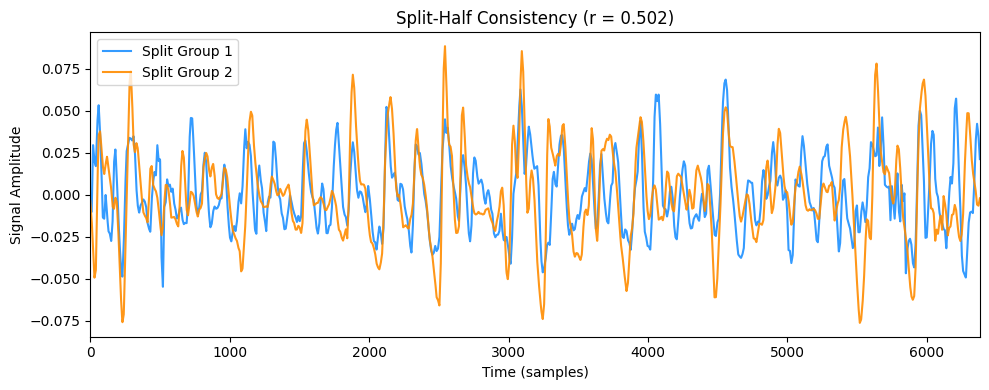

In [6]:

utils.segment_isc_utils.plot_split_half_comparison(df_pc)
